In [ ]:
# Step 1: Write down the two conditional probabilities and the prior.  Derive posterior probability (Bayes) truely in error as function of P.

# Events:
#Event 


**Events**

Event A: Bit is in error
Event B: Bit is flagged for being in error

Conditionl Probabilities:
 P(B|A) = 0.95
 P(B'|A') = 0.98

 Finding P(A|B) using Baye's Rule:


  $P(A|B) = \frac{0.95p}{0.95*p + 0.02* (1-P)}$

 


In [7]:
#Evaulate the posterior at:
#
#a) p = 0.1

def agivenb(p):
    result = (0.95*p)/(0.95*p+0.02*(1-p))
    return result

    
print("Solution at p = 0.1:", round(agivenb(0.1),3))
print("Solution at p = 0.01:", round(agivenb(0.01),3))
print("Solution at p = 0.001:", round(agivenb(0.001),3))

Solution at p = 0.1: 0.841
Solution at p = 0.01: 0.324
Solution at p = 0.001: 0.045


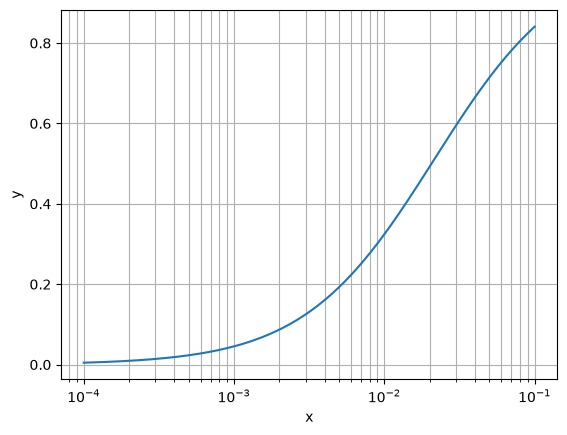

In [17]:
import numpy as np
import matplotlib.pyplot as plt

p = np.logspace(-4, -1, 200)
result = (0.95*p)/(0.95*p+0.02*(1-p))

plt.semilogx(p,result)

plt.xlabel("P")
plt.ylabel("Posterior")
plt.grid(True, which = "both")
plt.show()



Solution:  0.0206


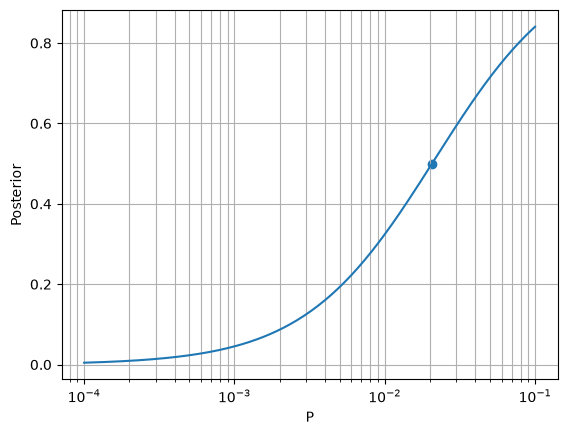

In [46]:
import sympy as sp


p = sp.symbols('p')
result = sp.Eq(0.5,(0.95*p)/(0.95*p+0.02*(1-p)))
x = sp.solve(result, p)



x_point = float(x[0])
y_point = 0.5
print("Solution: ", round(x_point, 4))
p = np.logspace(-4, -1, 200)
result = (0.95*p)/(0.95*p+0.02*(1-p))

plt.semilogx(p,result)
plt.scatter(x_point, y_point)

plt.xlabel("P")
plt.ylabel("Posterior")
plt.grid(True, which = "both")
plt.show()

**Using Monte Carlo**
Simulating sending a bunch of bits to see what happens

In [63]:
rng = np.random.default_rng(5)

def bsc(bits, p, rng):
    #my idea: randomly generate which positions are flipped.  Array of normal bits and rern array

    flippedBitsNum = int(round(len(bits)*p,1))

    for i in range(flippedBitsNum):
        #generate random number
        flipBit = rng.integers(0, len(bits) + 1)
        #flip bit in array
        bits[flipBit] ^= 1  #using XOR to flip it!

    return bits

# this function above will be called from seperate doc.  Let's pass in array of just ones

# the function below will act like our circuit.  For this example. I'll consider 0s as errors


def error_circuit(bits):
    flag = 0
    flagInError = 0
    for i in range(len(bits)):
        if bits[i] == 0:
            if rng.random() < 0.95:
                flag += 1
                flagInError += 1  #actually in error
        else:
           if rng.random() < 0.02:
                flag += 1
    #return ratio of flagged & in error to just flagged 
    ratio = flagInError/flag
    return ratio

array = np.ones(10**7, dtype=int)
ratio = error_circuit(bsc(array, 0.0206, rng))

            
print("The ratio of flagged bits in error to flagged bits is", round(ratio, 4))            

The ratio of flagged bits in error to flagged bits is 0.4943


If there is a good link and the number of bits in error is very low, the odds of the flag actually signifying an error is also very low.  For example, if p = 0.01, the flag will only be right 32.5% of the time.  Even though the circuit is 95% accurate, in reality, the when accounting for conditional probability, that number is much smaller than one would intuitively assume.